# 架构

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from typing import Optional, Tuple

class BertConfig:
    """BERT 配置类，对应 BERT-base 标准参数"""
    def __init__(
        self,
        vocab_size: int = 30522,        # 词表大小
        hidden_size: int = 768,         # 隐藏层维度
        num_hidden_layers: int = 12,    # Transformer Encoder 层数
        num_attention_heads: int = 12,  # 注意力头数
        intermediate_size: int = 3072,  # 前馈网络中间层维度（4*H）
        hidden_act: str = "gelu",       # 激活函数
        hidden_dropout_prob: float = 0.1,  # 全连接层 dropout
        attention_probs_dropout_prob: float = 0.1,  # 注意力 dropout
        max_position_embeddings: int = 512,  # 最大位置编码长度
        type_vocab_size: int = 2,       # 句子类型词表大小（0/1）
        initializer_range: float = 0.02, # 参数初始化标准差
        layer_norm_eps: float = 1e-12,  # LayerNorm epsilon
    ):
        self.vocab_size = vocab_size
        self.hidden_size = hidden_size
        self.num_hidden_layers = num_hidden_layers
        self.num_attention_heads = num_attention_heads
        self.intermediate_size = intermediate_size
        self.hidden_act = hidden_act
        self.hidden_dropout_prob = hidden_dropout_prob
        self.attention_probs_dropout_prob = attention_probs_dropout_prob
        self.max_position_embeddings = max_position_embeddings
        self.type_vocab_size = type_vocab_size
        self.initializer_range = initializer_range
        self.layer_norm_eps = layer_norm_eps
        # 每个头的维度
        self.head_dim = hidden_size // num_attention_heads

class BertEmbeddings(nn.Module):
    """
    BERT 嵌入层：词嵌入 + 分段嵌入 + 位置嵌入
    三者相加后经过 LayerNorm 和 Dropout
    """
    def __init__(self, config: BertConfig):
        super().__init__()
        self.word_embeddings = nn.Embedding(config.vocab_size, config.hidden_size, padding_idx=0)
        self.position_embeddings = nn.Embedding(config.max_position_embeddings, config.hidden_size)
        self.token_type_embeddings = nn.Embedding(config.type_vocab_size, config.hidden_size)

        self.LayerNorm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
        self.dropout = nn.Dropout(config.hidden_dropout_prob)

        # 注册位置索引缓冲区，避免每次前向都生成
        self.register_buffer(
            "position_ids",
            torch.arange(config.max_position_embeddings).expand((1, -1))
        )

    def forward(
        self,
        input_ids: torch.Tensor,
        token_type_ids: Optional[torch.Tensor] = None,
        position_ids: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        seq_length = input_ids.size(1)

        if position_ids is None:
            position_ids = self.position_ids[:, :seq_length]

        if token_type_ids is None:
            token_type_ids = torch.zeros_like(input_ids)

        words_emb = self.word_embeddings(input_ids)
        position_emb = self.position_embeddings(position_ids)
        token_type_emb = self.token_type_embeddings(token_type_ids)

        # 三种嵌入逐元素相加
        embeddings = words_emb + position_emb + token_type_emb
        embeddings = self.LayerNorm(embeddings)
        embeddings = self.dropout(embeddings)
        return embeddings

class BertSelfAttention(nn.Module):
    """多头自注意力层"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.num_attention_heads = config.num_attention_heads
        self.head_dim = config.head_dim
        self.all_head_size = self.num_attention_heads * self.head_dim

        # Q、K、V 三个线性变换
        self.query = nn.Linear(config.hidden_size, self.all_head_size)
        self.key = nn.Linear(config.hidden_size, self.all_head_size)
        self.value = nn.Linear(config.hidden_size, self.all_head_size)

        self.dropout = nn.Dropout(config.attention_probs_dropout_prob)

    def transpose_for_scores(self, x: torch.Tensor) -> torch.Tensor:
        """将 (batch, seq, hidden) 转为 (batch, heads, seq, head_dim)"""
        new_x_shape = x.size()[:-1] + (self.num_attention_heads, self.head_dim)
        x = x.view(*new_x_shape)
        return x.permute(0, 2, 1, 3)

    def forward(
        self,
        hidden_states: torch.Tensor,
        attention_mask: Optional[torch.Tensor] = None,
        output_attentions: bool = False,
    ) -> Tuple[torch.Tensor, Optional[torch.Tensor]]:
        # 生成 Q、K、V
        mixed_query_layer = self.query(hidden_states)
        mixed_key_layer = self.key(hidden_states)
        mixed_value_layer = self.value(hidden_states)

        # 分头
        query_layer = self.transpose_for_scores(mixed_query_layer)
        key_layer = self.transpose_for_scores(mixed_key_layer)
        value_layer = self.transpose_for_scores(mixed_value_layer)

        # 计算注意力分数: Q * K^T / sqrt(d_k)
        attention_scores = torch.matmul(query_layer, key_layer.transpose(-1, -2))
        attention_scores = attention_scores / math.sqrt(self.head_dim)

        # 应用注意力掩码（padding mask）
        if attention_mask is not None:
            attention_scores = attention_scores + attention_mask

        # Softmax 归一化
        attention_probs = F.softmax(attention_scores, dim=-1)
        attention_probs = self.dropout(attention_probs)

        # 加权求和 V
        context_layer = torch.matmul(attention_probs, value_layer)

        # 还原维度：(batch, heads, seq, head_dim) -> (batch, seq, hidden)
        context_layer = context_layer.permute(0, 2, 1, 3).contiguous()
        new_context_layer_shape = context_layer.size()[:-2] + (self.all_head_size,)
        context_layer = context_layer.view(*new_context_layer_shape)

        outputs = (context_layer, attention_probs) if output_attentions else (context_layer,)
        return outputs

class BertSelfOutput(nn.Module):
    """注意力后的输出层：Linear + Dropout + Residual + LayerNorm"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.dense = nn.Linear(config.hidden_size, config.hidden_size)
        self.LayerNorm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
        self.dropout = nn.Dropout(config.hidden_dropout_prob)

    def forward(self, hidden_states: torch.Tensor, input_tensor: torch.Tensor) -> torch.Tensor:
        hidden_states = self.dense(hidden_states)
        hidden_states = self.dropout(hidden_states)
        hidden_states = self.LayerNorm(hidden_states + input_tensor)  # 残差连接
        return hidden_states


class BertIntermediate(nn.Module):
    """前馈网络第一层：Linear + GELU"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.dense = nn.Linear(config.hidden_size, config.intermediate_size)
        self.intermediate_act_fn = F.gelu

    def forward(self, hidden_states: torch.Tensor) -> torch.Tensor:
        hidden_states = self.dense(hidden_states)
        hidden_states = self.intermediate_act_fn(hidden_states)
        return hidden_states


class BertOutput(nn.Module):
    """前馈网络第二层：Linear + Dropout + Residual + LayerNorm"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.dense = nn.Linear(config.intermediate_size, config.hidden_size)
        self.LayerNorm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
        self.dropout = nn.Dropout(config.hidden_dropout_prob)

    def forward(self, hidden_states: torch.Tensor, input_tensor: torch.Tensor) -> torch.Tensor:
        hidden_states = self.dense(hidden_states)
        hidden_states = self.dropout(hidden_states)
        hidden_states = self.LayerNorm(hidden_states + input_tensor)  # 残差连接
        return hidden_states

class BertLayer(nn.Module):
    """完整的一层 BERT Encoder：自注意力子层 + 前馈网络子层"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.attention = BertSelfAttention(config)
        self.attention_output = BertSelfOutput(config)
        self.intermediate = BertIntermediate(config)
        self.output = BertOutput(config)

    def forward(
        self,
        hidden_states: torch.Tensor,
        attention_mask: Optional[torch.Tensor] = None,
        output_attentions: bool = False,
    ) -> Tuple[torch.Tensor, Optional[torch.Tensor]]:
        # 子层1：多头自注意力 + 残差归一化
        self_attention_outputs = self.attention(
            hidden_states, attention_mask, output_attentions
        )
        attention_output = self_attention_outputs[0]
        attention_output = self.attention_output(attention_output, hidden_states)

        # 子层2：前馈网络 + 残差归一化
        intermediate_output = self.intermediate(attention_output)
        layer_output = self.output(intermediate_output, attention_output)

        outputs = (layer_output,) + self_attention_outputs[1:]
        return outputs

class BertEncoder(nn.Module):
    """多层 BertLayer 堆叠"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.layer = nn.ModuleList([BertLayer(config) for _ in range(config.num_hidden_layers)])

    def forward(
        self,
        hidden_states: torch.Tensor,
        attention_mask: Optional[torch.Tensor] = None,
        output_attentions: bool = False,
        output_hidden_states: bool = False,
    ) -> Tuple:
        all_hidden_states = () if output_hidden_states else None
        all_attentions = () if output_attentions else None

        for i, layer_module in enumerate(self.layer):
            if output_hidden_states:
                all_hidden_states = all_hidden_states + (hidden_states,)

            layer_outputs = layer_module(
                hidden_states, attention_mask, output_attentions
            )
            hidden_states = layer_outputs[0]

            if output_attentions:
                all_attentions = all_attentions + (layer_outputs[1],)

        if output_hidden_states:
            all_hidden_states = all_hidden_states + (hidden_states,)

        return tuple(v for v in [hidden_states, all_hidden_states, all_attentions] if v is not None)

class BertPooler(nn.Module):
    """提取 。CLS  表征并经过 Tanh 激活，用于分类任务"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.dense = nn.Linear(config.hidden_size, config.hidden_size)
        self.activation = nn.Tanh()

    def forward(self, hidden_states: torch.Tensor) -> torch.Tensor:
        # 取序列第一个 token（。CLS）
        first_token_tensor = hidden_states[:, 0]
        pooled_output = self.dense(first_token_tensor)
        pooled_output = self.activation(pooled_output)
        return pooled_output

class BertModel(nn.Module):
    """完整的 BERT 基础模型"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.config = config
        self.embeddings = BertEmbeddings(config)
        self.encoder = BertEncoder(config)
        self.pooler = BertPooler(config)

        # 参数初始化
        self.apply(self._init_weights)

    def _init_weights(self, module):
        """按原论文正态分布初始化参数"""
        if isinstance(module, nn.Linear):
            module.weight.data.normal_(mean=0.0, std=self.config.initializer_range)
            if module.bias is not None:
                module.bias.data.zero_()
        elif isinstance(module, nn.Embedding):
            module.weight.data.normal_(mean=0.0, std=self.config.initializer_range)
            if module.padding_idx is not None:
                module.weight.data[module.padding_idx].zero_()
        elif isinstance(module, nn.LayerNorm):
            module.bias.data.zero_()
            module.weight.data.fill_(1.0)

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: Optional[torch.Tensor] = None,
        token_type_ids: Optional[torch.Tensor] = None,
        position_ids: Optional[torch.Tensor] = None,
        output_attentions: bool = False,
        output_hidden_states: bool = False,
    ) -> Tuple:
        # 处理注意力掩码：扩展为 (batch, 1, 1, seq_len) 并转为加减形式
        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids)

        extended_attention_mask = attention_mask.unsqueeze(1).unsqueeze(2)
        extended_attention_mask = (1.0 - extended_attention_mask) * -10000.0

        # 嵌入层
        embedding_output = self.embeddings(
            input_ids=input_ids,
            token_type_ids=token_type_ids,
            position_ids=position_ids,
        )

        # 编码器
        encoder_outputs = self.encoder(
            embedding_output,
            attention_mask=extended_attention_mask,
            output_attentions=output_attentions,
            output_hidden_states=output_hidden_states,
        )

        sequence_output = encoder_outputs[0]
        pooled_output = self.pooler(sequence_output)

        outputs = (sequence_output, pooled_output) + encoder_outputs[1:]
        return outputs  # (last_hidden_state, pooled_output, hidden_states, attentions)

class BertLMPredictionHead(nn.Module):
    """MLM 任务预测头：预测被掩码位置的 token"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.dense = nn.Linear(config.hidden_size, config.hidden_size)
        self.transform_act_fn = F.gelu
        self.LayerNorm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
        # 输出层与词嵌入权重共享（原论文设计）
        self.decoder = nn.Linear(config.hidden_size, config.vocab_size, bias=False)
        self.bias = nn.Parameter(torch.zeros(config.vocab_size))

    def forward(self, hidden_states: torch.Tensor) -> torch.Tensor:
        hidden_states = self.dense(hidden_states)
        hidden_states = self.transform_act_fn(hidden_states)
        hidden_states = self.LayerNorm(hidden_states)
        hidden_states = self.decoder(hidden_states) + self.bias
        return hidden_states


class BertNSPHead(nn.Module):
    """NSP 任务预测头：二分类判断是否为下一句"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.seq_relationship = nn.Linear(config.hidden_size, 2)

    def forward(self, pooled_output: torch.Tensor) -> torch.Tensor:
        seq_relationship_score = self.seq_relationship(pooled_output)
        return seq_relationship_score


class BertForPreTraining(nn.Module):
    """BERT 预训练完整模型：MLM + NSP 双任务"""
    def __init__(self, config: BertConfig):
        super().__init__()
        self.config = config  # 新增：保存配置对象，修复 AttributeError
        self.bert = BertModel(config)
        self.cls = BertLMPredictionHead(config)
        self.seq_relationship = BertNSPHead(config)

        # 绑定 MLM 输出层与词嵌入权重（原论文标准设计）
        self.cls.decoder.weight = self.bert.embeddings.word_embeddings.weight

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: Optional[torch.Tensor] = None,
        token_type_ids: Optional[torch.Tensor] = None,
        masked_lm_labels: Optional[torch.Tensor] = None,
        next_sentence_label: Optional[torch.Tensor] = None,
    ) -> Tuple:
        outputs = self.bert(
            input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
        )

        sequence_output, pooled_output = outputs[:2]
        prediction_scores = self.cls(sequence_output)
        seq_relationship_score = self.seq_relationship(pooled_output)

        loss = None
        if masked_lm_labels is not None and next_sentence_label is not None:
            loss_fct = nn.CrossEntropyLoss(ignore_index=-100)
            masked_lm_loss = loss_fct(
                prediction_scores.view(-1, self.config.vocab_size),
                masked_lm_labels.view(-1)
            )
            next_sentence_loss = loss_fct(
                seq_relationship_score.view(-1, 2),
                next_sentence_label.view(-1)
            )
            loss = masked_lm_loss + next_sentence_loss

        output = (prediction_scores, seq_relationship_score) + outputs[2:]
        return ((loss,) + output) if loss is not None else output


class BertForSequenceClassification(nn.Module):
    """BERT 文本分类模型"""
    def __init__(self, config: BertConfig, num_labels: int = 2):
        super().__init__()
        self.num_labels = num_labels
        self.bert = BertModel(config)
        self.dropout = nn.Dropout(config.hidden_dropout_prob)
        self.classifier = nn.Linear(config.hidden_size, num_labels)

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: Optional[torch.Tensor] = None,
        token_type_ids: Optional[torch.Tensor] = None,
        labels: Optional[torch.Tensor] = None,
    ) -> Tuple:
        outputs = self.bert(
            input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
        )
        pooled_output = outputs[1]
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)

        loss = None
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits.view(-1, self.num_labels), labels.view(-1))

        return (loss, logits) if loss is not None else logits

if __name__ == "__main__":
    # 1. 初始化配置（BERT-base）
    config = BertConfig()

    # 2. 实例化基础 BERT 模型
    model = BertModel(config)
    model.eval()

    # 3. 构造输入
    batch_size = 2
    seq_len = 10
    input_ids = torch.randint(0, config.vocab_size, (batch_size, seq_len))
    attention_mask = torch.ones(batch_size, seq_len)
    token_type_ids = torch.zeros(batch_size, seq_len, dtype=torch.long)

    # 4. 基础模型前向传播
    with torch.no_grad():
        outputs = model(
            input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_attentions=True,
            output_hidden_states=True
        )

    last_hidden_state = outputs[0]  # (2, 10, 768)
    pooled_output = outputs[1]      # (2, 768)

    print(f"最后一层隐藏层形状: {last_hidden_state.shape}")
    print(f"CLS池化输出形状: {pooled_output.shape}")
    print(f"隐藏层层数: {len(outputs[2])}")
    print(f"注意力层数: {len(outputs[3])}")

    # 5. 测试预训练模型（关键字传参，避免顺序错误）
    pretrain_model = BertForPreTraining(config)

    # 构造 MLM 标签：仅掩码位置计算损失，其余用 -100 忽略
    masked_lm_labels = torch.randint(0, config.vocab_size, (batch_size, seq_len))
    masked_lm_labels[torch.rand(batch_size, seq_len) > 0.15] = -100  # 约15%位置被掩码

    # 构造 NSP 标签
    next_sentence_label = torch.randint(0, 2, (batch_size,))

    # 前向计算
    loss, mlm_scores, nsp_scores = pretrain_model(
        input_ids,
        attention_mask=attention_mask,
        token_type_ids=token_type_ids,
        masked_lm_labels=masked_lm_labels,
        next_sentence_label=next_sentence_label
    )

    print(f"\n预训练总损失: {loss.item():.4f}")
    print(f"MLM 预测形状: {mlm_scores.shape}")  # (2, 10, 30522)
    print(f"NSP 预测形状: {nsp_scores.shape}")  # (2, 2)


最后一层隐藏层形状: torch.Size([2, 10, 768])
CLS池化输出形状: torch.Size([2, 768])
隐藏层层数: 13
注意力层数: 12

预训练总损失: 10.6915
MLM 预测形状: torch.Size([2, 10, 30522])
NSP 预测形状: torch.Size([2, 2])



整体数据流总结
```
input_ids → 嵌入层（词+位置+分段） → 12层Transformer Encoder
                                              ↓
                          ┌───────────────────┴───────────────────┐
                          ↓                                       ↓
                所有token的序列表征                         CLS池化表征
                （用于MLM、NER等）                       （用于NSP、文本分类）

```



---


# 实战

In [5]:
!pip install nltk

使用设备: cuda
正在加载数据集...
训练集大小: 1600, 测试集大小: 400

开始训练...

===== Epoch 1/20 =====


Evaluating: 100%|██████████| 25/25 [00:01<00:00, 17.37it/s]


训练损失: 0.6993 | 训练准确率: 0.5056
测试损失: 0.6940 | 测试准确率: 0.4950

===== Epoch 2/20 =====


Evaluating: 100%|██████████| 25/25 [00:01<00:00, 18.23it/s]


训练损失: 0.6969 | 训练准确率: 0.4975
测试损失: 0.6939 | 测试准确率: 0.5050

===== Epoch 3/20 =====


...

训练损失: 0.0024 | 训练准确率: 1.0000
测试损失: 1.6990 | 测试准确率: 0.6325

===== Epoch 19/20 =====


Evaluating: 100%|██████████| 25/25 [00:01<00:00, 18.89it/s]


训练损失: 0.0017 | 训练准确率: 1.0000
测试损失: 1.7810 | 测试准确率: 0.6400

===== Epoch 20/20 =====


Evaluating: 100%|██████████| 25/25 [00:01<00:00, 18.37it/s]


训练损失: 0.0014 | 训练准确率: 1.0000
测试损失: 1.8361 | 测试准确率: 0.6400

绘制训练曲线...


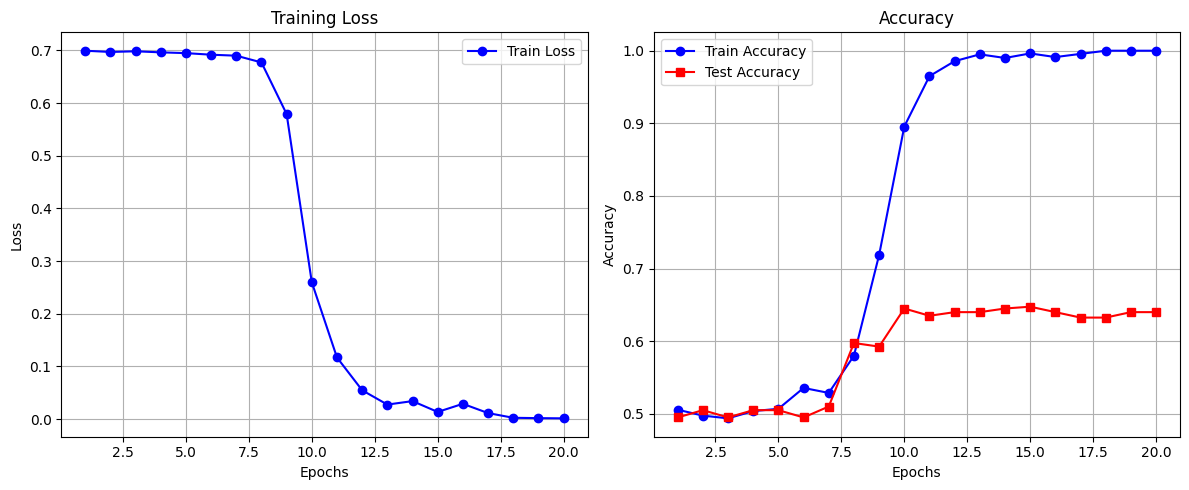

训练完成，曲线图已保存为 bert_training_metrics.png


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import numpy as np
import matplotlib.pyplot as plt
from typing import Optional, Tuple
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer
from tqdm import tqdm
import random
import nltk


# ===================== 1. BERT 核心模型代码（修复版） =====================
class BertConfig:
    def __init__(
        self,
        vocab_size: int = 30522,
        hidden_size: int = 256,       # 小模型：256维，方便快速训练
        num_hidden_layers: int = 4,    # 小模型：4层
        num_attention_heads: int = 4,  # 小模型：4头
        intermediate_size: int = 1024, # 4*hidden_size
        hidden_act: str = "gelu",
        hidden_dropout_prob: float = 0.1,
        attention_probs_dropout_prob: float = 0.1,
        max_position_embeddings: int = 128, # 最大序列长度设128，加速训练
        type_vocab_size: int = 2,
        initializer_range: float = 0.02,
        layer_norm_eps: float = 1e-12,
    ):
        self.vocab_size = vocab_size
        self.hidden_size = hidden_size
        self.num_hidden_layers = num_hidden_layers
        self.num_attention_heads = num_attention_heads
        self.intermediate_size = intermediate_size
        self.hidden_act = hidden_act
        self.hidden_dropout_prob = hidden_dropout_prob
        self.attention_probs_dropout_prob = attention_probs_dropout_prob
        self.max_position_embeddings = max_position_embeddings
        self.type_vocab_size = type_vocab_size
        self.initializer_range = initializer_range
        self.layer_norm_eps = layer_norm_eps
        self.head_dim = hidden_size // num_attention_heads


class BertEmbeddings(nn.Module):
    def __init__(self, config: BertConfig):
        super().__init__()
        self.word_embeddings = nn.Embedding(config.vocab_size, config.hidden_size, padding_idx=0)
        self.position_embeddings = nn.Embedding(config.max_position_embeddings, config.hidden_size)
        self.token_type_embeddings = nn.Embedding(config.type_vocab_size, config.hidden_size)
        self.LayerNorm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
        self.dropout = nn.Dropout(config.hidden_dropout_prob)
        self.register_buffer("position_ids", torch.arange(config.max_position_embeddings).expand((1, -1)))

    def forward(self, input_ids, token_type_ids=None, position_ids=None):
        seq_length = input_ids.size(1)
        if position_ids is None:
            position_ids = self.position_ids[:, :seq_length]
        if token_type_ids is None:
            token_type_ids = torch.zeros_like(input_ids)
        embeddings = self.word_embeddings(input_ids) + self.position_embeddings(position_ids) + self.token_type_embeddings(token_type_ids)
        embeddings = self.LayerNorm(embeddings)
        embeddings = self.dropout(embeddings)
        return embeddings


class BertSelfAttention(nn.Module):
    def __init__(self, config: BertConfig):
        super().__init__()
        self.num_attention_heads = config.num_attention_heads
        self.head_dim = config.head_dim
        self.all_head_size = self.num_attention_heads * self.head_dim
        self.query = nn.Linear(config.hidden_size, self.all_head_size)
        self.key = nn.Linear(config.hidden_size, self.all_head_size)
        self.value = nn.Linear(config.hidden_size, self.all_head_size)
        self.dropout = nn.Dropout(config.attention_probs_dropout_prob)

    def transpose_for_scores(self, x):
        new_x_shape = x.size()[:-1] + (self.num_attention_heads, self.head_dim)
        x = x.view(*new_x_shape)
        return x.permute(0, 2, 1, 3)

    def forward(self, hidden_states, attention_mask=None, output_attentions=False):
        mixed_query_layer = self.query(hidden_states)
        mixed_key_layer = self.key(hidden_states)
        mixed_value_layer = self.value(hidden_states)
        query_layer = self.transpose_for_scores(mixed_query_layer)
        key_layer = self.transpose_for_scores(mixed_key_layer)
        value_layer = self.transpose_for_scores(mixed_value_layer)

        attention_scores = torch.matmul(query_layer, key_layer.transpose(-1, -2)) / math.sqrt(self.head_dim)
        if attention_mask is not None:
            attention_scores = attention_scores + attention_mask
        attention_probs = F.softmax(attention_scores, dim=-1)
        attention_probs = self.dropout(attention_probs)
        context_layer = torch.matmul(attention_probs, value_layer)

        context_layer = context_layer.permute(0, 2, 1, 3).contiguous()
        new_context_layer_shape = context_layer.size()[:-2] + (self.all_head_size,)
        context_layer = context_layer.view(*new_context_layer_shape)
        outputs = (context_layer, attention_probs) if output_attentions else (context_layer,)
        return outputs


class BertSelfOutput(nn.Module):
    def __init__(self, config: BertConfig):
        super().__init__()
        self.dense = nn.Linear(config.hidden_size, config.hidden_size)
        self.LayerNorm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
        self.dropout = nn.Dropout(config.hidden_dropout_prob)

    def forward(self, hidden_states, input_tensor):
        hidden_states = self.dense(hidden_states)
        hidden_states = self.dropout(hidden_states)
        hidden_states = self.LayerNorm(hidden_states + input_tensor)
        return hidden_states


class BertIntermediate(nn.Module):
    def __init__(self, config: BertConfig):
        super().__init__()
        self.dense = nn.Linear(config.hidden_size, config.intermediate_size)
        self.intermediate_act_fn = F.gelu

    def forward(self, hidden_states):
        hidden_states = self.dense(hidden_states)
        hidden_states = self.intermediate_act_fn(hidden_states)
        return hidden_states


class BertOutput(nn.Module):
    def __init__(self, config: BertConfig):
        super().__init__()
        self.dense = nn.Linear(config.intermediate_size, config.hidden_size)
        self.LayerNorm = nn.LayerNorm(config.hidden_size, eps=config.layer_norm_eps)
        self.dropout = nn.Dropout(config.hidden_dropout_prob)

    def forward(self, hidden_states, input_tensor):
        hidden_states = self.dense(hidden_states)
        hidden_states = self.dropout(hidden_states)
        hidden_states = self.LayerNorm(hidden_states + input_tensor)
        return hidden_states


class BertLayer(nn.Module):
    def __init__(self, config: BertConfig):
        super().__init__()
        self.attention = BertSelfAttention(config)
        self.attention_output = BertSelfOutput(config)
        self.intermediate = BertIntermediate(config)
        self.output = BertOutput(config)

    def forward(self, hidden_states, attention_mask=None, output_attentions=False):
        self_attention_outputs = self.attention(hidden_states, attention_mask, output_attentions)
        attention_output = self_attention_outputs[0]
        attention_output = self.attention_output(attention_output, hidden_states)
        intermediate_output = self.intermediate(attention_output)
        layer_output = self.output(intermediate_output, attention_output)
        outputs = (layer_output,) + self_attention_outputs[1:]
        return outputs


class BertEncoder(nn.Module):
    def __init__(self, config: BertConfig):
        super().__init__()
        self.layer = nn.ModuleList([BertLayer(config) for _ in range(config.num_hidden_layers)])

    def forward(self, hidden_states, attention_mask=None, output_attentions=False, output_hidden_states=False):
        all_hidden_states = () if output_hidden_states else None
        all_attentions = () if output_attentions else None
        for i, layer_module in enumerate(self.layer):
            if output_hidden_states:
                all_hidden_states = all_hidden_states + (hidden_states,)
            layer_outputs = layer_module(hidden_states, attention_mask, output_attentions)
            hidden_states = layer_outputs[0]
            if output_attentions:
                all_attentions = all_attentions + (layer_outputs[1],)
        if output_hidden_states:
            all_hidden_states = all_hidden_states + (hidden_states,)
        return tuple(v for v in [hidden_states, all_hidden_states, all_attentions] if v is not None)


class BertPooler(nn.Module):
    def __init__(self, config: BertConfig):
        super().__init__()
        self.dense = nn.Linear(config.hidden_size, config.hidden_size)
        self.activation = nn.Tanh()

    def forward(self, hidden_states):
        first_token_tensor = hidden_states[:, 0]
        pooled_output = self.dense(first_token_tensor)
        pooled_output = self.activation(pooled_output)
        return pooled_output


class BertModel(nn.Module):
    def __init__(self, config: BertConfig):
        super().__init__()
        self.config = config
        self.embeddings = BertEmbeddings(config)
        self.encoder = BertEncoder(config)
        self.pooler = BertPooler(config)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            module.weight.data.normal_(mean=0.0, std=self.config.initializer_range)
            if module.bias is not None:
                module.bias.data.zero_()
        elif isinstance(module, nn.Embedding):
            module.weight.data.normal_(mean=0.0, std=self.config.initializer_range)
            if module.padding_idx is not None:
                module.weight.data[module.padding_idx].zero_()
        elif isinstance(module, nn.LayerNorm):
            module.bias.data.zero_()
            module.weight.data.fill_(1.0)

    def forward(self, input_ids, attention_mask=None, token_type_ids=None, output_attentions=False, output_hidden_states=False):
        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids)
        extended_attention_mask = attention_mask.unsqueeze(1).unsqueeze(2)
        extended_attention_mask = (1.0 - extended_attention_mask) * -10000.0
        embedding_output = self.embeddings(input_ids, token_type_ids)
        encoder_outputs = self.encoder(embedding_output, extended_attention_mask, output_attentions, output_hidden_states)
        sequence_output = encoder_outputs[0]
        pooled_output = self.pooler(sequence_output)
        outputs = (sequence_output, pooled_output) + encoder_outputs[1:]
        return outputs


class BertForSequenceClassification(nn.Module):
    def __init__(self, config: BertConfig, num_labels: int = 2):
        super().__init__()
        self.config = config
        self.num_labels = num_labels
        self.bert = BertModel(config)
        self.dropout = nn.Dropout(config.hidden_dropout_prob)
        self.classifier = nn.Linear(config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask=None, token_type_ids=None, labels=None):
        outputs = self.bert(input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids)
        pooled_output = outputs[1]
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)
        loss = None
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits.view(-1, self.num_labels), labels.view(-1))
        return (loss, logits) if loss is not None else logits


# ===================== 2. 数据集构建 =====================
class ImdbDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        # 分词：截断+填充到max_len
        encoding = self.tokenizer(
            text,
            max_length=self.max_len,
            truncation=True,
            padding='max_length',
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'token_type_ids': encoding['token_type_ids'].squeeze(0),
            'label': torch.tensor(label, dtype=torch.long)
        }


def load_imdb_data(train_size=1600, test_size=400):
    """
    加载 NLTK 官方真实电影评论情感数据集（二分类）
    共2000条真实评论文本，正负情感各1000条，是情感分类领域经典基准数据集
    返回格式与原IMDB完全兼容
    """
    # 首次运行自动下载数据集，后续自动读取本地缓存
    nltk.download('movie_reviews', quiet=True)
    from nltk.corpus import movie_reviews

    all_texts = []
    all_labels = []
    for label_type in movie_reviews.categories():
        for file_id in movie_reviews.fileids(label_type):
            # 将单词列表拼接为完整文本
            review_text = " ".join(movie_reviews.words(file_id))
            all_texts.append(review_text)
            # 正面情感标签为1，负面为0
            all_labels.append(1 if label_type == "pos" else 0)

    # 固定随机种子打乱数据集
    combined = list(zip(all_texts, all_labels))
    random.seed(42)
    random.shuffle(combined)
    all_texts, all_labels = zip(*combined)
    all_texts, all_labels = list(all_texts), list(all_labels)

    # 划分训练集和测试集
    train_texts = all_texts[:train_size]
    train_labels = all_labels[:train_size]
    test_texts = all_texts[train_size : train_size + test_size]
    test_labels = all_labels[train_size : train_size + test_size]

    return train_texts, train_labels, test_texts, test_labels



# ===================== 3. 训练与评估函数 =====================
def train_epoch(model, dataloader, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    pbar = tqdm(dataloader, desc="Training")
    for batch in pbar:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        token_type_ids = batch["token_type_ids"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()
        loss, logits = model(input_ids, attention_mask, token_type_ids, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        preds = torch.argmax(logits, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        pbar.set_postfix({"loss": f"{loss.item():.4f}", "acc": f"{correct/total:.4f}"})

    avg_loss = total_loss / len(dataloader)
    avg_acc = correct / total
    return avg_loss, avg_acc


def evaluate(model, dataloader, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Evaluating"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            token_type_ids = batch["token_type_ids"].to(device)
            labels = batch["label"].to(device)

            loss, logits = model(input_ids, attention_mask, token_type_ids, labels)
            total_loss += loss.item()
            preds = torch.argmax(logits, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(dataloader)
    avg_acc = correct / total
    return avg_loss, avg_acc


# ===================== 4. 绘图函数 =====================
def plot_metrics(train_losses, train_accs, test_accs):
    epochs = range(1, len(train_losses)+1)
    plt.figure(figsize=(12, 5))

    # 损失曲线
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, 'b-o', label='Train Loss')
    plt.title('Training Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.legend()

    # 准确率曲线
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accs, 'b-o', label='Train Accuracy')
    plt.plot(epochs, test_accs, 'r-s', label='Test Accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.savefig('bert_training_metrics.png')
    plt.show()


# ===================== 5. 主程序：运行训练 =====================
if __name__ == "__main__":
    # 超参数（NLTK movie_reviews 共2000条，按8:2拆分）
    MAX_LEN = 128
    BATCH_SIZE = 16
    EPOCHS = 20
    LR = 2e-5
    TRAIN_SIZE = 1600  # 训练集1600条
    TEST_SIZE = 400    # 测试集400条，总和刚好2000

    # 设备自动选择
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"使用设备: {device}")

    # 1. 加载分词器和数据
    print("正在加载数据集...")
    tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
    train_texts, train_labels, test_texts, test_labels = load_imdb_data(TRAIN_SIZE, TEST_SIZE)
    print(f"训练集大小: {len(train_texts)}, 测试集大小: {len(test_texts)}")

    # 2. 构建数据集和数据加载器
    train_dataset = ImdbDataset(train_texts, train_labels, tokenizer, MAX_LEN)
    test_dataset = ImdbDataset(test_texts, test_labels, tokenizer, MAX_LEN)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # 3. 初始化模型
    config = BertConfig(max_position_embeddings=MAX_LEN)


    model = BertForSequenceClassification(config, num_labels=2)
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)

    # 4. 训练循环
    train_losses = []
    train_accs = []
    test_accs = []

    print("\n开始训练...")
    for epoch in range(1, EPOCHS+1):
        print(f"\n===== Epoch {epoch}/{EPOCHS} =====")
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, device)
        test_loss, test_acc = evaluate(model, test_loader, device)

        train_losses.append(train_loss)
        train_accs.append(train_acc)
        test_accs.append(test_acc)

        print(f"训练损失: {train_loss:.4f} | 训练准确率: {train_acc:.4f}")
        print(f"测试损失: {test_loss:.4f} | 测试准确率: {test_acc:.4f}")

    # 5. 绘制结果图
    print("\n绘制训练曲线...")
    plot_metrics(train_losses, train_accs, test_accs)
    print("训练完成，曲线图已保存为 bert_training_metrics.png")
